# 02 · PAD-UFES-20 — acquisition and EDA

**Project:** Skin Lesion Triage · BIU DS23 Capstone  
**Owner:** Data hat · **Charter section:** 2 (operating point), 3 (Data), and the risk rows on missingness, leakage and self-reported answers

PAD-UFES-20 is the project's target-domain smartphone dataset and the only source containing the
structured symptom fields used by the app: itch, grew, hurt, changed, bleed and elevation.

A patient-level split is frozen before any target-aware development. Train and validation patients
are used for EDA and model development; the held-out test patients are reserved for final evaluation.

## What this notebook does
1. Loads the published PAD-UFES-20 metadata.
2. Creates the patient-level train / validation / test split once, then loads and verifies it on every later run.
3. Audits missingness and symptom associations on development data only.
4. Audits skin-tone coverage.
5. Re-measures the metadata-only baseline with cross-validation on development patients (variants A–D).
6. Measures that baseline on validation patients at the charter's operating point (flag budget, prevalence).
7. Measures how much it loses when a share of the answers is wrong, as self-reported answers may be.
8. Audits leakage from naive image-level splitting and verifies the frozen split.

## Reference dataset counts
| | |
|---|---|
| Images | 2,298 |
| Raw `lesion_id` values | 1,641 |
| Patients | 1,373 |
| Melanoma images | 52 |

## Outputs
| File | Contents |
|---|---|
| `data/raw/pad_metadata_raw.csv` | metadata exactly as published |
| `data/processed/pad_split.csv` | frozen patient-level split manifest (created once, never overwritten) |
| `data/processed/baseline_metadata_val.csv` | metadata baseline on validation patients, 9 slot × prevalence scenarios |
| `data/processed/val_scores_metadata.csv` | per-patient validation scores, for paired comparison with the image and fusion models |
| `reports/figures/02_*.png` | EDA figures |

In [1]:
# Cell 1 · Configuration (identical in every notebook)
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    PROJECT = "/content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers"
else:
    PROJECT = os.path.abspath("..")

RAW       = os.path.join(PROJECT, "data", "raw")
PROCESSED = os.path.join(PROJECT, "data", "processed")
FIGURES   = os.path.join(PROJECT, "reports", "figures")

# Where the image archive is stored. Kept as its own setting so the heavy files can later move to a
# shared folder without touching anything else. Colab addresses Drive by path, never by the id in a
# share link, so any override below must be a path under /content/drive/MyDrive/.
IMAGES_DIR = os.path.join(RAW, "images")

for d in (RAW, PROCESSED, FIGURES, IMAGES_DIR):
    os.makedirs(d, exist_ok=True)

SEED = 42              # every split in this project uses this seed
IMG_SIZE = 512         # long side, in pixels, for the training copy of the images

print("project  :", PROJECT)
print("raw      :", RAW)
print("processed:", PROCESSED)
print("images   :", IMAGES_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
project  : /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers
raw      : /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/data/raw
processed: /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/data/processed
images   : /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/data/raw/images


In [2]:
# Cell 2 · Download the real metadata from Mendeley
# urllib, not requests: Mendeley's file server rejects the requests user-agent with HTTP 403.
import urllib.request, pandas as pd

PAD_URL = ("https://data.mendeley.com/public-files/datasets/zr7vgbcyr2/files/"
           "fa850265-57da-48f0-ba3e-998b3e44b1f6/file_downloaded")
PAD_CSV = os.path.join(RAW, "pad_metadata_raw.csv")

if not os.path.exists(PAD_CSV):
    try:
        req = urllib.request.Request(PAD_URL, headers={"User-Agent": "DS23-capstone"})
        with urllib.request.urlopen(req, timeout=120) as r:
            open(PAD_CSV, "wb").write(r.read())
        print("downloaded")
    except Exception as e:
        print(f"automatic download failed: {e}")
        print("Open the DOI page in a browser, download metadata.csv, and upload it here:")
        if IN_COLAB:
            from google.colab import files
            open(PAD_CSV, "wb").write(next(iter(files.upload().values())))

pad = pd.read_csv(PAD_CSV)
print(f"\n{pad.shape[0]:,} rows x {pad.shape[1]} columns")
print("\ncolumns:", list(pad.columns))
pad.head(3)



2,298 rows x 26 columns

columns: ['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,False,False,False,False,False,False,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,True,True,False,True,True,True,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1545_1867_547.png,False


In [3]:
# Cell 3 · Structure, targets and stable lesion identifier

import numpy as np

# PAD stores missing values as empty strings or the literal 'UNK'
pad = pad.replace({"UNK": np.nan, "": np.nan})

print(f"images        : {len(pad):,}")
print(f"raw lesion ids: {pad['lesion_id'].nunique():,}")
print(f"patients      : {pad['patient_id'].nunique():,}")

MAP = {
    "MEL": "melanoma",
    "BCC": "bcc",
    "SCC": "scc",
    "NEV": "nevus",
    "SEK": "sk",
    "ACK": "ak"
}

pad["cls"] = pad["diagnostic"].map(MAP)

assert pad["cls"].notna().all(), \
    f"unmapped diagnostic codes: {sorted(pad.loc[pad['cls'].isna(), 'diagnostic'].unique())}"

# Frozen project target:
# malignant = melanoma + basal cell carcinoma + squamous cell carcinoma
# ACK is treated as non-malignant.
pad["is_malignant"] = (
    pad["cls"].isin(["melanoma", "bcc", "scc"])
).astype(int)

pad["is_melanoma"] = (
    pad["cls"] == "melanoma"
).astype(int)

SYMPTOMS = [
    "itch",
    "grew",
    "hurt",
    "changed",
    "bleed",
    "elevation"
]

print("\nper class:")
print(pad["cls"].value_counts(dropna=False).to_string())

print(f"\nmelanoma images : {int(pad['is_melanoma'].sum())}")
print(f"malignant share : {100 * pad['is_malignant'].mean():.1f}%")

print(
    f"\nimages per patient: "
    f"max {pad.groupby('patient_id').size().max()}, "
    f"median {pad.groupby('patient_id').size().median():.0f}"
)

# lesion_id is reused across some patients in PAD,
# so the operational lesion identifier is patient_id + lesion_id.
assert pad["patient_id"].notna().all()
assert pad["lesion_id"].notna().all()

pad["lesion_key"] = (
    pad["patient_id"].astype(str)
    + "::"
    + pad["lesion_id"].astype(str)
)

shared = pad.groupby("lesion_id")["patient_id"].nunique()

print(
    f"\nraw lesion_id values              : "
    f"{pad['lesion_id'].nunique():,}"
)

print(
    f"lesion_ids reused across patients : "
    f"{int((shared > 1).sum()):,}"
)

print(
    f"patient-lesion keys               : "
    f"{pad['lesion_key'].nunique():,}"
)


images        : 2,298
raw lesion ids: 1,641
patients      : 1,373

per class:
cls
bcc         845
ak          730
nevus       244
sk          235
scc         192
melanoma     52

melanoma images : 52
malignant share : 47.4%

images per patient: max 10, median 1

raw lesion_id values              : 1,641
lesion_ids reused across patients : 250
patient-lesion keys               : 1,891


In [4]:
# Cell 4 · Freeze the PAD patient split BEFORE target-aware EDA
# The split is generated ONCE. Every later run loads and verifies the saved manifest;
# it is never regenerated, so a library upgrade or a re-run cannot silently move patients.
from sklearn.model_selection import train_test_split

PAD_SPLIT = os.path.join(PROCESSED, "pad_split.csv")

patients = (
    pad.groupby("patient_id")
       .agg(has_malignant=("is_malignant", "max"),
            has_melanoma=("is_melanoma", "max"))
       .reset_index()
)
patients["stratum"] = np.select(
    [patients["has_melanoma"] == 1, patients["has_malignant"] == 1],
    ["melanoma", "other_malignant"],
    default="non_malignant",
)

if os.path.exists(PAD_SPLIT):
    frozen = pd.read_csv(PAD_SPLIT)
    assert set(frozen["img_id"]) == set(pad["img_id"]), \
        "PAD metadata no longer matches the frozen manifest - investigate before continuing"
    assert frozen.groupby("patient_id")["split"].nunique().max() == 1, \
        "a patient appears in more than one split"
    split_map = frozen.groupby("patient_id")["split"].first().to_dict()
    created = False
    print("Frozen split LOADED from:", PAD_SPLIT)
else:
    dev_patients, test_patients = train_test_split(
        patients, test_size=0.20, random_state=SEED, stratify=patients["stratum"])
    train_patients, val_patients = train_test_split(
        dev_patients, test_size=0.20, random_state=SEED, stratify=dev_patients["stratum"])
    split_map = {
        **{p: "train" for p in train_patients["patient_id"]},
        **{p: "val"   for p in val_patients["patient_id"]},
        **{p: "test"  for p in test_patients["patient_id"]},
    }
    created = True

pad["split"] = pad["patient_id"].map(split_map)
patients["split"] = patients["patient_id"].map(split_map)
assert pad["split"].notna().all(), "a patient in the metadata is missing from the split manifest"

if created:
    pad[["img_id", "patient_id", "lesion_id", "lesion_key", "diagnostic",
         "is_malignant", "is_melanoma", "split"]].to_csv(PAD_SPLIT, index=False)
    print("Frozen split CREATED and saved to:", PAD_SPLIT)

# The charter quotes these numbers; any drift stops the notebook. This matters most on a machine
# where pad_split.csv did not exist and the split was just generated: a different scikit-learn
# version can stratify differently, and the manifest must not be overwritten on a guess.
n_test_img = int((pad["split"] == "test").sum())
n_test_pat = int((patients["split"] == "test").sum())
assert (n_test_img, n_test_pat) == (501, 275), (
    f"frozen split does not match the charter: {n_test_img} test images / {n_test_pat} test "
    f"patients, expected 501 / 275. "
    + ("The split was just CREATED on this machine, so the library's stratified split differs "
       "from the one the charter was written against. Investigate before continuing; do not "
       "overwrite pad_split.csv."
       if created else
       "The split was LOADED from pad_split.csv, so either the metadata or the manifest changed."))

print("Image-level split:")
print(pad.groupby("split").agg(images=("img_id", "size"),
                               patients=("patient_id", "nunique"),
                               malignant_images=("is_malignant", "sum"),
                               melanoma_images=("is_melanoma", "sum")))
print("\nPatient-level targets:")
print(patients.groupby("split").agg(patients=("patient_id", "size"),
                                    malignant_patients=("has_malignant", "sum"),
                                    melanoma_patients=("has_melanoma", "sum")))

for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = (set(pad.loc[pad["split"] == a, "patient_id"])
               & set(pad.loc[pad["split"] == b, "patient_id"]))
    assert not overlap, f"{len(overlap)} patients appear in both {a} and {b}"

Frozen split LOADED from: /content/drive/MyDrive/לימודים/Data Science/Skin Lesion Triage for Healthcare Providers/data/processed/pad_split.csv
Image-level split:
       images  patients  malignant_images  melanoma_images
split                                                     
test      501       275               238                9
train    1440       878               675               35
val       357       220               176                8

Patient-level targets:
       patients  malignant_patients  melanoma_patients
split                                                 
test        275                 129                  7
train       878                 411                 23
val         220                 103                  6


In [5]:
# Cell 4b · Development/test subsets and lesion-level analysis table

dev = pad[
    pad["split"].isin(["train", "val"])
].copy()

test = pad[
    pad["split"] == "test"
].copy()

# Metadata and symptom fields describe the lesion/case,
# not each individual photograph.
# Keep one row per patient-lesion for target-aware metadata EDA.
dev_lesions = (
    dev.sort_values("img_id")
       .drop_duplicates("lesion_key")
       .copy()
)

test_lesions = (
    test.sort_values("img_id")
        .drop_duplicates("lesion_key")
        .copy()
)

print(f"Development images  : {len(dev):,}")
print(f"Development lesions : {len(dev_lesions):,}")

print(f"\nTest images         : {len(test):,}")
print(f"Test lesions        : {len(test_lesions):,}")

Development images  : 1,797
Development lesions : 1,489

Test images         : 501
Test lesions        : 402


In [6]:
# Cell 4c · Verify metadata consistency within each patient-lesion

LESION_FIELDS = [
    "diagnostic",
    "age",
    "region",
    "itch",
    "grew",
    "hurt",
    "changed",
    "bleed",
    "elevation"
]

print("Fields that vary across images of the same patient-lesion:")

found_issue = False

for c in LESION_FIELDS:
    n_unique = (
        dev.groupby("lesion_key")[c]
           .nunique(dropna=False)
    )

    inconsistent = int((n_unique > 1).sum())

    if inconsistent > 0:
        found_issue = True
        print(f"{c:<12}: {inconsistent} lesions")

if not found_issue:
    print("None ✓")

Fields that vary across images of the same patient-lesion:
None ✓


## 1 · Missingness — the finding the whole design rests on

In PAD, the optional fields (smoking, family history, Fitzpatrick type, measured diameter) were recorded
mainly for patients who went on to biopsy — that is, mostly for the cancers. So **"this field is empty"
predicts the label**, for reasons that are administrative rather than medical.

A model given those fields learns *"missing = benign"*. In the app every user fills the same mandatory form,
that pattern will not exist, and the accuracy evaporates on the first real patient.

Restricting the model to the fields the app always asks is necessary but **not sufficient**: Cell 6b shows
that two of the mandatory symptom answers are missing in the same label-related way. The rule is therefore
stricter: **no missingness indicator ever reaches a model**.

**Who filled the form, and how the labels were made** (Pacheco et al., *Data in Brief* 2020):
- All visit data were entered by senior medical students; the symptom fields record the patient's answers
  *during the appointment*. App users will answer alone, so the questionnaire numbers here are measured on
  cleaner input than deployment will see (tested in Cell 8c).
- 58.4% of lesions are biopsy-proven, including 100% of the cancers; most NEV, SEK and ACK are clinical
  diagnoses. Benign labels are therefore noisier than malignant ones, and the optional fields were filled
  mainly on the biopsy pathway — the missingness pattern measured below.

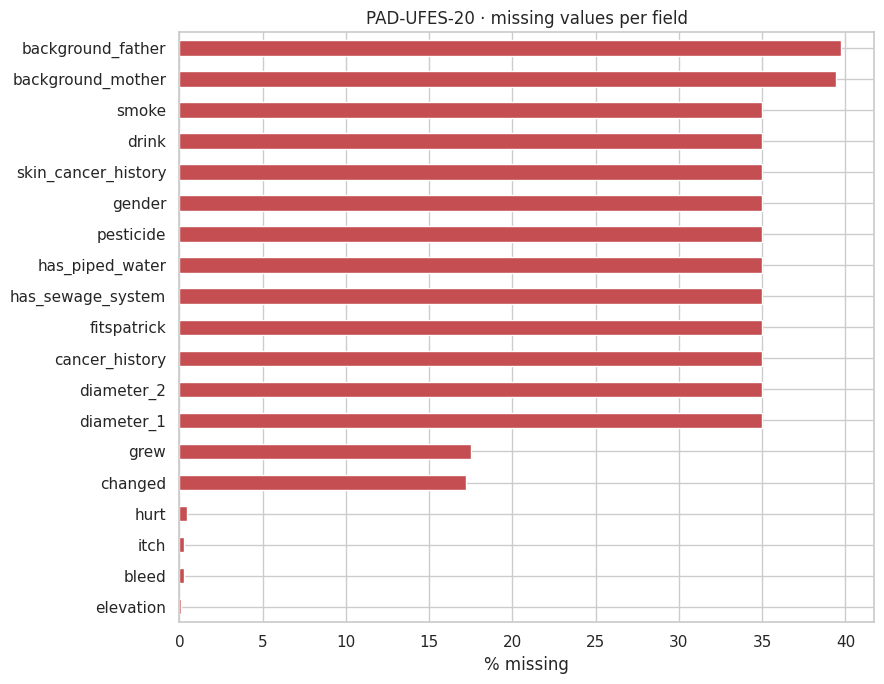

% missing by class — development lesions only:
cls                    ak  bcc  melanoma  nevus  scc    sk
background_father    65.0  5.0      10.0   78.0  7.0  86.0
background_mother    65.0  5.0      10.0   78.0  6.0  86.0
smoke                62.0  0.0       0.0   72.0  0.0  82.0
drink                62.0  0.0       0.0   72.0  0.0  82.0
skin_cancer_history  62.0  0.0       0.0   72.0  0.0  82.0
gender               62.0  0.0       0.0   72.0  0.0  82.0
pesticide            62.0  0.0       0.0   72.0  0.0  82.0
has_piped_water      62.0  0.0       0.0   72.0  0.0  82.0
has_sewage_system    62.0  0.0       0.0   72.0  0.0  82.0
fitspatrick          62.0  0.0       0.0   72.0  0.0  82.0


In [7]:
# Cell 5 · Missingness and label-related missingness

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Descriptive overview of the published PAD image rows
miss_all = (
    pad.isna()
       .mean()
       .mul(100)
       .sort_values(ascending=False)
)

plt.figure(figsize=(9, 7))

miss_all[miss_all > 0].plot.barh(
    color="#C44E52"
)

plt.gca().invert_yaxis()
plt.xlabel("% missing")
plt.title("PAD-UFES-20 · missing values per field")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES,
        "02_pad_missing.png"
    ),
    dpi=120
)

plt.show()

# Target-aware analysis:
# development lesions only
print(
    "% missing by class — "
    "development lesions only:"
)

miss_dev = (
    dev_lesions.isna()
               .mean()
               .mul(100)
               .sort_values(ascending=False)
)

by_cls = (
    dev_lesions.groupby("cls")
               .apply(
                   lambda g:
                   g.isna()
                    .mean()
                    .mul(100)
                    .round(0),
                   include_groups=False
               )
)

cols_to_show = [
    c
    for c in miss_dev.index[:10]
    if c in by_cls.columns
]

print(
    by_cls[cols_to_show]
    .T
    .to_string()
)


## 2 · The symptoms

These six questions correspond to the symptom fields considered for the app.
Because their association with the diagnosis is target-aware, the analysis below is restricted to
development lesions only.

The table reports associations with overall malignancy and with melanoma separately.
These are descriptive development-set findings and are not used as clinical rules.


In [8]:
# Cell 6 · Symptom rates against malignancy and melanoma
# One row per patient-lesion; development split only.

rows = []

for c in SYMPTOMS:

    s = (
        dev_lesions[c]
        .astype(str)
        .str.upper()
    )

    for val in ["TRUE", "FALSE"]:

        m = s == val

        if m.any():

            rows.append({
                "field": c,
                "answer": val,
                "n": int(m.sum()),

                "% malignant": round(
                    100
                    * dev_lesions.loc[
                        m,
                        "is_malignant"
                    ].mean(),
                    1
                ),

                "% melanoma": round(
                    100
                    * dev_lesions.loc[
                        m,
                        "is_melanoma"
                    ].mean(),
                    1
                )
            })

    rows.append({
        "field": c,
        "answer": "missing",
        "n": int(
            dev_lesions[c]
            .isna()
            .sum()
        ),
        "% malignant": np.nan,
        "% melanoma": np.nan
    })

tab = (
    pd.DataFrame(rows)
      .set_index(
          ["field", "answer"]
      )
)

print(
    "Symptom rates — "
    "development lesions only"
)

print(
    tab.to_string()
)


Symptom rates — development lesions only
                      n  % malignant  % melanoma
field     answer                                
itch      TRUE      941         51.1         0.4
          FALSE     543         31.5         4.6
          missing     5          NaN         NaN
grew      TRUE      536         53.7         3.7
          FALSE     651         15.8         0.3
          missing   302          NaN         NaN
hurt      TRUE      231         83.5         0.0
          FALSE    1253         36.6         2.3
          missing     5          NaN         NaN
changed   TRUE      109         67.9        15.6
          FALSE    1082         29.4         0.6
          missing   298          NaN         NaN
bleed     TRUE      360         83.1         0.0
          FALSE    1124         31.3         2.6
          missing     5          NaN         NaN
elevation TRUE      893         60.1         0.9
          FALSE     594         19.7         3.4
          missing     2     

In [9]:
# Cell 6b · Is missingness in the mandatory fields label-related too?
overall = dev_lesions["is_malignant"].mean()
print("Missing mandatory fields — development lesions only:")
for c in SYMPTOMS:
    m = dev_lesions[c].isna()
    if m.sum():
        print(f"{c:<10} missing in {m.sum():>4} lesions | "
              f"{100 * dev_lesions.loc[m, 'is_malignant'].mean():5.1f}% malignant "
              f"(overall {100 * overall:.1f}%)")

any_missing = dev_lesions[SYMPTOMS].isna().any(axis=1)
both = dev_lesions["grew"].isna() & dev_lesions["changed"].isna()
print(f"\nlesions missing >= 1 symptom answer : {int(any_missing.sum())} "
      f"({100 * any_missing.mean():.0f}%), "
      f"{100 * dev_lesions.loc[any_missing, 'is_malignant'].mean():.1f}% malignant")
print(f"grew AND changed both missing       : {int(both.sum())}")
print(f"malignant lesions a complete-case analysis drops: "
      f"{int(dev_lesions.loc[any_missing, 'is_malignant'].sum())} of "
      f"{int(dev_lesions['is_malignant'].sum())}")
print("\nclass mix of lesions with a missing answer:")
print(dev_lesions.loc[any_missing, "cls"].value_counts().to_string())

Missing mandatory fields — development lesions only:
itch       missing in    5 lesions |  60.0% malignant (overall 44.0%)
grew       missing in  302 lesions |  87.4% malignant (overall 44.0%)
hurt       missing in    5 lesions |  60.0% malignant (overall 44.0%)
changed    missing in  298 lesions |  88.3% malignant (overall 44.0%)
bleed      missing in    5 lesions |  80.0% malignant (overall 44.0%)
elevation  missing in    2 lesions |  50.0% malignant (overall 44.0%)

lesions missing >= 1 symptom answer : 304 (20%), 87.5% malignant
grew AND changed both missing       : 296
malignant lesions a complete-case analysis drops: 266 of 655

class mix of lesions with a missing answer:
cls
bcc         200
scc          57
nevus        26
melanoma      9
sk            8
ak            4


**Finding.** The "mandatory" fields are not clean in PAD: `grew` and `changed` are missing for ~20% of development lesions, and 87–88% of those are malignant. A missingness indicator on these two fields leaks the label just as the optional fields do.

**Rule.** No model ever receives a missingness indicator; missing answers are imputed inside the CV pipeline. The app makes all six answers mandatory, so the pattern cannot exist at deployment. Complete-case results describe a population with far fewer cancers (32.8% vs. 44.0% malignant) and are always reported next to the all-lesion imputed result (variant D, Cell 8).

Fitzpatrick type — full PAD dataset (1 = lightest):
fitspatrick
1.0    153
2.0    876
3.0    392
4.0     62
5.0     10
6.0      1
NaN    804

Fitzpatrick V-VI coverage by split:
       images  patients
split                  
test        2         2
train       8         6
val         1         1

Fitzpatrick V-VI — development patients only:
patients           : 7
malignant patients : 4
melanoma patients  : 0


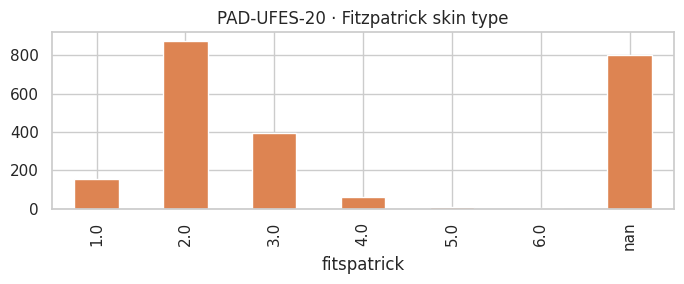

In [10]:
# Cell 7 · Skin tone — what this dataset can and cannot support

if "fitspatrick" in pad.columns:

    # Full-dataset descriptive distribution
    ft_all = (
        pad["fitspatrick"]
        .value_counts(
            dropna=False
        )
        .sort_index()
    )

    print(
        "Fitzpatrick type — "
        "full PAD dataset "
        "(1 = lightest):"
    )

    print(
        ft_all.to_string()
    )

    # Label-free V-VI coverage by split
    dark_all = pad[
        pad["fitspatrick"].isin([5, 6])
    ]

    print(
        "\nFitzpatrick V-VI coverage "
        "by split:"
    )

    print(
        dark_all.groupby("split")
        .agg(
            images=("img_id", "size"),
            patients=("patient_id", "nunique")
        )
        .to_string()
    )

    # Target-aware subgroup description:
    # development patients only
    dark_dev = dev[
        dev["fitspatrick"].isin([5, 6])
    ].copy()

    dark_dev_patients = (
        dark_dev.groupby("patient_id")
        .agg(
            malignant=(
                "is_malignant",
                "max"
            ),
            melanoma=(
                "is_melanoma",
                "max"
            )
        )
    )

    print(
        "\nFitzpatrick V-VI — "
        "development patients only:"
    )

    print(
        f"patients           : "
        f"{len(dark_dev_patients)}"
    )

    print(
        f"malignant patients : "
        f"{int(dark_dev_patients['malignant'].sum())}"
    )

    print(
        f"melanoma patients  : "
        f"{int(dark_dev_patients['melanoma'].sum())}"
    )

    plt.figure(figsize=(7, 3))

    ft_all.plot.bar(
        color="#DD8452"
    )

    plt.title(
        "PAD-UFES-20 · Fitzpatrick skin type"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURES,
            "02_pad_fitzpatrick.png"
        ),
        dpi=120
    )

    plt.show()


## 3 · The metadata baseline, re-measured

The charter first quoted a provisional AUC of 0.90 for a metadata-only model, measured before the
missingness artefact was controlled for, and later 0.883.

Four variants, on development lesions only, with patient-grouped stratified 5-fold cross-validation:

| Variant | What it tells us |
|---|---|
| A · missing-as-category | the app-field model with the missingness artefact left in |
| B · complete-case | clean, but on a population with far fewer cancers: it drops 266 of 655 malignant lesions (Cell 6b). **This is the population notebook 04 models**, which declines to score an incomplete form |
| C · missing-count only | how predictive the administrative missingness pattern is by itself |
| **D · all lesions, imputed, no indicator** | **the honest baseline**: the same population as the test set, no missingness signal |

Cells 8b–8c then leave cross-validation for the frozen train → validation split, at the charter's
operating point. The held-out PAD test patients remain untouched.

In [11]:
# Cell 8 · Metadata development baseline — four variants
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

num_fields = ["age"]
cat_fields = ["region"] + SYMPTOMS
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)


def auc(df, num, cat, name, missing_as_category=True):
    X = df[num + cat].copy()
    for c in cat:
        if missing_as_category:
            X[c] = X[c].astype(str)                       # NaN becomes its own category "nan"
        else:
            X[c] = X[c].map(lambda v: np.nan if pd.isna(v) else str(v)).astype(object)

    transformers = []
    if num:
        transformers.append((make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num))
    if cat:
        steps = [] if missing_as_category else [SimpleImputer(strategy="most_frequent")]
        transformers.append((make_pipeline(*steps,
                                           OneHotEncoder(handle_unknown="ignore", min_frequency=10)),
                             cat))

    model = make_pipeline(make_column_transformer(*transformers),
                          LogisticRegression(max_iter=2000, class_weight="balanced"))
    scores = cross_val_score(model, X, df["is_malignant"],
                             groups=df["patient_id"].astype(str), cv=cv, scoring="roc_auc")
    print(f"{name:<52} AUC {scores.mean():.3f} +/- {scores.std():.3f} "
          f"(lesions={len(df):,}, malignant={100 * df['is_malignant'].mean():.1f}%)")
    return scores.mean()


# A · missing kept as a category (contains the missingness artefact)
a = auc(dev_lesions, num_fields, cat_fields, "A · all lesions, missing as a category")

# B · complete cases only (clean, but a different, less malignant population)
complete = dev_lesions.dropna(subset=SYMPTOMS + ["region", "age"])
b = auc(complete, num_fields, cat_fields, "B · complete-case lesions")

# D · all lesions, missing imputed inside the pipeline, no indicator (same population as test)
d_ = auc(dev_lesions, num_fields, cat_fields, "D · all lesions, imputed, no indicator",
         missing_as_category=False)

# C · missingness of the optional fields alone
OPTIONAL = [c for c in ["smoke", "drink", "pesticide", "skin_cancer_history", "cancer_history",
                        "has_piped_water", "has_sewage_system", "fitspatrick", "diameter_1"]
            if c in dev_lesions.columns]
baseline_df = dev_lesions.assign(n_missing=dev_lesions[OPTIONAL].isna().sum(axis=1))
c_ = auc(baseline_df, ["n_missing"], [], "C · missing optional-field count only")

dropped = dev_lesions.loc[~dev_lesions.index.isin(complete.index)]
print(f"\ncomplete lesions: {len(complete):,} of {len(dev_lesions):,} "
      f"({100 * len(complete) / len(dev_lesions):.0f}%)")
print(f"malignant lesions dropped by complete-case: {int(dropped['is_malignant'].sum())} "
      f"of {int(dev_lesions['is_malignant'].sum())}")

A · all lesions, missing as a category               AUC 0.916 +/- 0.018 (lesions=1,489, malignant=44.0%)
B · complete-case lesions                            AUC 0.893 +/- 0.029 (lesions=1,185, malignant=32.8%)
D · all lesions, imputed, no indicator               AUC 0.860 +/- 0.021 (lesions=1,489, malignant=44.0%)
C · missing optional-field count only                AUC 0.839 +/- 0.012 (lesions=1,489, malignant=44.0%)

complete lesions: 1,185 of 1,489 (80%)
malignant lesions dropped by complete-case: 266 of 655


In [12]:
# Cell 8b · Metadata baseline at the operating point: train patients -> validation patients
# The test split stays closed. Scores are saved so the image and fusion models can later be
# compared with this baseline on exactly the same validation patients (paired bootstrap).
from sklearn.metrics import roc_auc_score

DAILY_ARRIVALS = 100                 # stated assumption (charter, section 2)
SLOT_SCENARIOS = [5, 10, 15]         # urgent slots per day
PREVALENCES    = [0.05, 0.10, 0.20]  # malignant share of the waiting list
N_BOOT = 2000
rng = np.random.default_rng(SEED)


def prep(df):
    """App fields only; answers normalised to 'TRUE'/'FALSE', missing kept as NaN (imputed later)."""
    X = df[num_fields + cat_fields].copy()
    for c in cat_fields:
        X[c] = X[c].map(lambda v: np.nan if pd.isna(v) else str(v).strip().upper()).astype(object)
    return X


def metadata_model():
    """Variant D from Cell 8: imputation inside the pipeline, no missingness indicator."""
    return make_pipeline(
        make_column_transformer(
            (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_fields),
            (make_pipeline(SimpleImputer(strategy="most_frequent"),
                           OneHotEncoder(handle_unknown="ignore", min_frequency=10)), cat_fields)),
        LogisticRegression(max_iter=2000, class_weight="balanced"))


def to_patients(lesions, scores):
    """Frozen aggregation rule: a patient's risk is the maximum over their lesions."""
    return (lesions.assign(score=np.asarray(scores))
                   .groupby("patient_id")
                   .agg(y=("is_malignant", "max"), score=("score", "max")))


def at_budget(y, s, prevalence, budget):
    """Flag the top `budget` share of a queue whose malignant share is `prevalence`.
    Patients are reweighted to that prevalence. Returns sensitivity, PPV and flag rate."""
    y, s = np.asarray(y), np.asarray(s)
    n_pos = y.sum()
    w = np.where(y == 1, prevalence / n_pos, (1 - prevalence) / (len(y) - n_pos))
    order = np.argsort(-s, kind="stable")
    w_o, y_o = w[order], y[order]
    flagged = np.cumsum(w_o) <= budget + 1e-12
    sens = w_o[flagged & (y_o == 1)].sum() / prevalence
    flag_rate = w_o[flagged].sum()
    ppv = prevalence * sens / flag_rate if flag_rate > 0 else np.nan
    return sens, ppv, flag_rate


def boot_ci(y, s, metric, n=N_BOOT):
    """95% CI by resampling patients within each class."""
    y, s = np.asarray(y), np.asarray(s)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    vals = [metric(y[idx], s[idx]) for idx in
            (np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
             for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])


tr = dev_lesions[dev_lesions["split"] == "train"]
va = dev_lesions[dev_lesions["split"] == "val"]

meta_model = metadata_model().fit(prep(tr), tr["is_malignant"])
val_pat = to_patients(va, meta_model.predict_proba(prep(va))[:, 1])

auc_val = roc_auc_score(val_pat["y"], val_pat["score"])
lo, hi = boot_ci(val_pat["y"], val_pat["score"], roc_auc_score)
print(f"validation patients: {len(val_pat)} ({int(val_pat['y'].sum())} malignant)")
print(f"patient-level AUC  : {auc_val:.3f}  (95% CI {lo:.3f}-{hi:.3f})\n")

rows = []
for slots in SLOT_SCENARIOS:
    budget = slots / DAILY_ARRIVALS
    for p in PREVALENCES:
        sens, ppv, fr = at_budget(val_pat["y"], val_pat["score"], p, budget)
        s_lo, s_hi = boot_ci(val_pat["y"], val_pat["score"],
                             lambda yy, ss: at_budget(yy, ss, p, budget)[0], n=500)
        rows.append({"slots/day": slots, "flag budget": budget, "prevalence": p,
                     "sensitivity ceiling": min(1.0, budget / p),
                     "sensitivity": round(sens, 3), "sens 95% CI": f"{s_lo:.2f}-{s_hi:.2f}",
                     "PPV": round(ppv, 3), "flag rate": round(fr, 3)})

baseline_table = pd.DataFrame(rows)
print(baseline_table.to_string(index=False))

baseline_table.to_csv(os.path.join(PROCESSED, "baseline_metadata_val.csv"), index=False)
val_pat.to_csv(os.path.join(PROCESSED, "val_scores_metadata.csv"))
print("\nsaved: baseline_metadata_val.csv, val_scores_metadata.csv")

validation patients: 220 (103 malignant)
patient-level AUC  : 0.867  (95% CI 0.818-0.912)

 slots/day  flag budget  prevalence  sensitivity ceiling  sensitivity sens 95% CI   PPV  flag rate
         5         0.05        0.05                 1.00        0.505   0.35-0.58 0.509      0.050
         5         0.05        0.10                 0.50        0.408   0.26-0.50 0.841      0.048
         5         0.05        0.20                 0.25        0.243   0.21-0.24 1.000      0.049
        10         0.10        0.05                 1.00        0.573   0.46-0.70 0.306      0.094
        10         0.10        0.10                 1.00        0.524   0.44-0.65 0.532      0.099
        10         0.10        0.20                 0.50        0.417   0.36-0.50 0.859      0.097
        15         0.15        0.05                 1.00        0.660   0.56-0.77 0.225      0.147
        15         0.15        0.10                 1.00        0.650   0.51-0.73 0.435      0.150
        15        

In [13]:
# Cell 8c · How much does the baseline lose if patients, not clinicians, answer the form?
# In PAD the answers were recorded by senior medical students during the visit. In the app the
# patient answers alone. We flip a share of the answered symptom questions on the validation
# patients only (the model is not retrained) and measure the drop.
FLIP_SHARE, N_REPEATS = 0.10, 50
REF_PREVALENCE, REF_BUDGET = 0.10, 10 / DAILY_ARRIVALS   # primary scenario

# Own random stream, created here rather than reused from Cell 8b. That generator has already
# been consumed by 6,500 bootstrap draws, so sharing it makes these numbers depend on N_BOOT and
# on whether 8b ran first. Seeded inside this cell, so re-running it reproduces exactly.
rng_flip = np.random.default_rng(SEED + 1)


def flip_answers(X, share, rng, direction="both"):
    """direction='both' flips TRUE<->FALSE at random; 'over' only turns FALSE into TRUE
    (an anxious patient over-reporting)."""
    X = X.copy()
    for c in SYMPTOMS:
        eligible = X[c].isin(["TRUE", "FALSE"] if direction == "both" else ["FALSE"])
        idx = X.index[eligible]
        pick = rng.choice(idx, size=int(round(share * len(idx))), replace=False)
        X.loc[pick, c] = X.loc[pick, c].map({"TRUE": "FALSE", "FALSE": "TRUE"})
    return X


Xv = prep(va)
clean_auc = auc_val
clean_sens = at_budget(val_pat["y"], val_pat["score"], REF_PREVALENCE, REF_BUDGET)[0]

for direction in ["both", "over"]:
    aucs, senss = [], []
    for _ in range(N_REPEATS):
        noisy = to_patients(va, meta_model.predict_proba(
            flip_answers(Xv, FLIP_SHARE, rng_flip, direction))[:, 1])
        aucs.append(roc_auc_score(noisy["y"], noisy["score"]))
        senss.append(at_budget(noisy["y"], noisy["score"], REF_PREVALENCE, REF_BUDGET)[0])
    print(f"{int(FLIP_SHARE * 100)}% answers flipped ({direction:>4}) | "
          f"AUC {clean_auc:.3f} -> {np.mean(aucs):.3f} "
          f"[{np.percentile(aucs, 5):.3f}-{np.percentile(aucs, 95):.3f}] | "
          f"sensitivity@{REF_BUDGET:.0%} budget, {REF_PREVALENCE:.0%} prevalence: "
          f"{clean_sens:.3f} -> {np.mean(senss):.3f}")

10% answers flipped (both) | AUC 0.867 -> 0.823 [0.795-0.846] | sensitivity@10% budget, 10% prevalence: 0.524 -> 0.464
10% answers flipped (over) | AUC 0.867 -> 0.835 [0.819-0.858] | sensitivity@10% budget, 10% prevalence: 0.524 -> 0.490


**Interpretation (validation patients, train → val, test untouched).**
- **Two baselines, for two different questions.** A model that must score every lesion — imputing
  the 304 incomplete forms, with no missingness indicator — reaches **AUC 0.860** (variant D,
  development CV) at 100% coverage. A model restricted to complete forms reaches **0.893**
  (variant B) at 80% coverage, on a population that is 32.8% malignant rather than 44.0%. Neither
  is wrong; they describe different populations, and **notebook 04 builds the second kind**, so
  its held-out score belongs beside 0.893. Variant A reaches 0.916 by keeping missingness as a
  category: the 0.056 between A and D is the size of the administrative artefact.
- On the frozen validation split variant D reaches a **patient-level AUC of 0.867
  (95% CI 0.818–0.912)**, 220 patients, 103 malignant.
- **At the primary operating point** (10 slots for 100 arrivals, 10% prevalence) the questionnaire alone puts **52% of malignant patients** on the daily list (95% CI 0.44–0.65), with **PPV 0.53** and a flag rate of 9.9%. The ceiling there is 1.00, so about half of the cancers are still missed.
- **The ceiling binds at higher prevalence.** At 20% prevalence and 10 slots no model can exceed 0.50; the questionnaire reaches 0.42, i.e. 83% of what is possible. With 5 slots and 20% prevalence it reaches 0.24 of a 0.25 ceiling, with PPV 1.00: the most confident questionnaire cases are almost all cancers.
- **Self-reported answers cost real sensitivity.** Flipping 10% of answers at random lowers AUC from 0.867 to **0.823** and sensitivity at the primary operating point from 0.52 to **0.46**; over-reporting only ("no" → "yes") lowers them to **0.835** and **0.49**. The questionnaire numbers above are therefore an upper bound for the app.
- These validation scores are saved per patient (`val_scores_metadata.csv`). The image and fusion models are compared with them on the same 220 patients, which answers how much the photo adds beyond the questionnaire.

In [14]:
# Cell 9 · Leakage from a naive image-level split
from sklearn.model_selection import train_test_split

d = pad.dropna(subset=["patient_id", "lesion_id"]).copy()

# Deliberately naive, and deliberately named apart from the real `tr` in Cell 8b, which this
# would otherwise overwrite with something completely different.
naive_tr, naive_te = train_test_split(d, test_size=0.20, random_state=SEED)

# A test image leaks if another image of the same patient-lesion appears in train.
leaked = naive_te["lesion_key"].isin(set(naive_tr["lesion_key"])).mean()
multi = d.groupby("lesion_key").size().gt(1).mean()

print(f"patient-lesions with more than one image: {100 * multi:.1f}%")
print(f"naive image split -> {100 * leaked:.1f}% of test images have the same lesion in train")

# Audit the actual frozen split: no patient and no patient-lesion may cross a boundary.
SPLITS = ["train", "val", "test"]
patient_sets = {s: set(pad.loc[pad["split"] == s, "patient_id"]) for s in SPLITS}
lesion_sets  = {s: set(pad.loc[pad["split"] == s, "lesion_key"]) for s in SPLITS}

for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    shared_patients = patient_sets[a] & patient_sets[b]
    assert not shared_patients, f"{len(shared_patients)} patients appear in both {a} and {b}"

    shared_lesions = lesion_sets[a] & lesion_sets[b]
    assert not shared_lesions, f"{len(shared_lesions)} patient-lesions appear in both {a} and {b}"

print("Frozen split audit passed: no patient or patient-lesion overlap.")

patient-lesions with more than one image: 19.1%
naive image split -> 29.3% of test images have the same lesion in train
Frozen split audit passed: no patient or patient-lesion overlap.


## 4 · Images

This notebook does not load image pixels.

**Metadata** comes from the official Mendeley release (Cell 2). **The photographs do not**:
anonymous bulk download from Mendeley is blocked from Colab, so the 2,298 PNG files in
`data/raw/images/pad_original/` are fetched from a public mirror
(`SalmaneExploring/pad-ufes-20` on Hugging Face). Notebook 01 downloads them, and the identical
cell exists in notebook 03, so either can run first.

The mirror is verified on content, not on filenames: notebook 03 Cell 5e checks that every one of
the 2,298 files is the same photograph as its counterpart in PAD's own copy inside ISIC
(collection 406), carrying the same malignant flag.

In notebook 01 the full ISIC clinical collection — including PAD's ISIC copy — is downloaded, and
only the 6,539-image ISIC training pool is packed into `images_isic_512.tar`. The PAD photographs
are used there label-free: pixel statistics and image grids on development patients only, and the
ISIC ↔ PAD overlap audit on all patients. They enter modelling through the frozen split created here.

## 5 · Domain comparison

The ISIC-versus-PAD image-domain comparison is documented in Section 6 of
`01_eda_isic.ipynb`, where the image files are already available.

This notebook focuses on PAD metadata, splitting and development-set EDA.

## Summary

### Dataset and frozen split
| Check | Actual |
|---|---|
| Images · patients | **2,298 · 1,373** |
| Raw `lesion_id` values · reused across patients | **1,641 · 250** |
| Patient-lesion keys (`patient_id::lesion_id`) | **1,891** |
| Melanoma images · malignant share (MEL+BCC+SCC) | **52 · 47.4%** |
| Frozen split · images | train 1,440 · val 357 · **test 501** |
| Frozen split · patients | train 878 · val 220 · **test 275** |
| Malignant patients | train 411 · val 103 · **test 129** |
| Melanoma | train 35 images / 23 patients · val 8 / 6 · **test 9 images / 7 patients** |
| Development · test patient-lesions | **1,489 · 402** |
| Split created once, then loaded and verified | ✓ (`pad_split.csv` never overwritten) |
| Frozen split overlap (patients and patient-lesions) | **0** ✓ |
| Patient-lesions with >1 image · naive image-split leakage | **19.1% · 29.3%** |

### Missingness (development lesions)
| Check | Actual |
|---|---|
| Missing optional-field count alone | **AUC 0.839 ± 0.012** |
| `grew` missing | **302 lesions, 87.4% malignant** (overall 44.0%) |
| `changed` missing | **298 lesions, 88.3% malignant** (overall 44.0%) |
| Complete-case lesions | **1,185 of 1,489 (80%)**, 32.8% malignant |
| Malignant lesions dropped by complete-case | **266 of 655** |
| Rule | no missingness indicator ever reaches a model; missing answers are imputed inside the pipeline |
| Who filled the form | senior medical students during the visit (Pacheco et al. 2020); 100% of cancers biopsy-proven |

### Symptoms (development lesions)
| Check | Actual |
|---|---|
| `changed` → melanoma | **15.6% TRUE vs 0.6% FALSE** |
| `bleed` → malignant | **83.1% TRUE** vs 31.3% FALSE |
| `hurt` → malignant | **83.5% TRUE** vs 36.6% FALSE |
| `grew` → malignant | **53.7% TRUE** vs 15.8% FALSE |

### Metadata baseline · cross-validation on development patients
| Check | Actual |
|---|---|
| A · missing as category (1,489 lesions, 100% coverage) | **0.916 ± 0.018** — contains the artefact |
| **D · all lesions, imputed, no indicator (100% coverage)** | **0.860 ± 0.021** ← the floor for a model that scores everyone |
| **B · complete-case (1,185 lesions, 80% coverage, 32.8% malignant)** | **0.893 ± 0.029** ← the floor for a model that declines incomplete forms, as notebook 04 does |
| C · missing optional-field count only | **0.839 ± 0.012** — the artefact measured on its own |
| A − D | **0.056**: the size of the administrative artefact |

### Metadata baseline · validation patients at the operating point (100 arrivals/day, test untouched)
| Check | Actual |
|---|---|
| Patient-level AUC (train → val, max over lesions) | **0.867** (95% CI 0.818–0.912) · 220 patients, 103 malignant |
| **10 slots · 10% prevalence (primary)** | sensitivity **0.52** (0.44–0.65) · PPV **0.53** · flag rate 9.9% · ceiling 1.00 |
| 10 slots · 5% prevalence | sensitivity 0.57 (0.46–0.70) · PPV 0.31 · ceiling 1.00 |
| 10 slots · 20% prevalence | sensitivity 0.42 (0.36–0.50) · PPV 0.86 · ceiling 0.50 |
| 5 slots · 10% / 20% prevalence | sensitivity 0.41 / 0.24 · PPV 0.84 / 1.00 · ceiling 0.50 / 0.25 |
| 15 slots · 10% / 20% prevalence | sensitivity 0.65 / 0.52 · PPV 0.44 / 0.72 · ceiling 1.00 / 0.75 |
| 10% answers flipped at random | AUC 0.867 → **0.823** · primary sensitivity 0.52 → **0.46** |
| 10% answers flipped "no" → "yes" only | AUC 0.867 → **0.835** · primary sensitivity 0.52 → **0.49** |
| Saved for the image / fusion comparison | `baseline_metadata_val.csv`, `val_scores_metadata.csv` |

### Skin tone
| Check | Actual |
|---|---|
| Fitzpatrick recorded | **65%** of images (804 of 2,298 missing) |
| Fitzpatrick V–VI | **11 images total · 9 dev · 2 test** |
| Fitzpatrick V–VI · dev | **7 patients, 4 malignant, 0 melanoma** |

**Next:** `03_preprocessing.ipynb` — frozen manifests and modelling inputs (ISIC 6,404 images after exclusions; PAD frozen split).